# 01 First run: the processor on one small file

This notebook runs `SidmProcessor` on a 200-event signal file that is committed to the
repository, `tests/data/events_2mu2e_500GeV_200ev.root`, taken from the signal sample
`2Mu2E_500GeV_1p2GeV_1p9mm`. You will:

1. pick a channel (a selection) and a histogram collection,
2. run the processor,
3. print the cutflow and draw one histogram,
4. walk through everything the processor returns.

It needs no grid proxy, no EOS access and no CVMFS correction files: the input file and
copies of the correction files are in `tests/data/`. It runs in one process, chunk by
chunk, with coffea's `IterativeExecutor`.

**Kernel:** `SIDM (LCG_107 Py3.11)`, the kernel registered in step 4 of the top
[README](../README.md#getting-started-on-lpc).

**To run it without opening it**, from the repository root with the environment active
(`source sidm_venv/bin/activate`):

```bash
jupyter nbconvert --to notebook --execute --output-dir /tmp tutorials/01_first_run.ipynb
```

This writes the executed copy to `/tmp/01_first_run.ipynb` and leaves the tracked notebook
as it is.

## 1. Setup

The first cell finds the repository this notebook sits in and puts it first on the
Python path, so `import sidm` loads the code of this checkout even when the venv has a
different copy installed (the printed `sidm package` line tells you which one you got).

It also sets `SIDM_CORRECTIONS_ROOT`. The processor applies the standard CMS corrections
to simulation by default and reads their files from CVMFS; this variable points it at
the copies in `tests/data/corrections/` instead (`sidm/tools/corrections.py`, class
`Corrections`). On a machine with CVMFS you can drop that line.

In [1]:
import os
import sys
import subprocess
import tempfile
from pathlib import Path

import hist
import matplotlib.pyplot as plt


def find_repo_root(start):
    # the first directory at or above start that holds sidm/ and tests/data/
    for path in [start, *start.parents]:
        if (path / "sidm" / "__init__.py").is_file() and (path / "tests" / "data").is_dir():
            return path
    raise RuntimeError(f"no SIDM checkout at or above {start}; start Jupyter inside the repository")


REPO = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO))
os.environ["SIDM_CORRECTIONS_ROOT"] = str(REPO / "tests" / "data" / "corrections")

import sidm
from sidm import BASE_DIR
from sidm.tools import sidm_processor, llpnanoaodschema, utilities
from coffea import processor
import coffea.util

utilities.set_plot_style(dpi=100)
print("repository: ", REPO)
print("sidm package:", Path(sidm.__file__).parent)

repository:  /uscms_data/d3/murtazas/tutorial_run/SIDM
sidm package: /uscms_data/d3/murtazas/tutorial_run/SIDM/sidm


## 2. Choose a channel and a histogram collection

A **lepton jet** (LJ) is the analysis object of this search: a jet clustered from the
muons, DSA (displaced standalone) muons, electrons and photons of the event, meant to
collect the collimated decay products of one dark photon.

A **channel** is a named selection in `sidm/configs/selections.yaml`: object cuts
(`obj_cuts`, applied before the lepton jets are built), optional cuts on the lepton jets
and the objects built from them (`postLj_obj_cuts`), and event cuts (`evt_cuts`). Only
entries with an `obj_cuts` block can be run; the others are fragments that channels
include through YAML anchors.

A **histogram collection** is a named list of histograms in
`sidm/configs/hist_collections.yaml`. Each name in the list is a key of `hist_defs` in
`sidm/definitions/hists.py`, which says how the histogram is binned and filled.

The processor takes a list of each. This notebook uses one of each so the output stays
small.

In [2]:
selections = utilities.load_yaml(f"{BASE_DIR}/configs/selections.yaml")
collections = utilities.load_yaml(f"{BASE_DIR}/configs/hist_collections.yaml")

channels = sorted(name for name, sel in selections.items()
                  if isinstance(sel, dict) and "obj_cuts" in sel)
print(f"{len(channels)} channels, for example:", ", ".join(channels[:12]))
print(f"{len(collections)} histogram collections, for example:", ", ".join(list(collections)[:12]))

127 channels, for example: 2LJ_CC, 2LJ_CC_charge, 2mu2e, 2mu2e_matchedLj, 2mu2e_noMuPtCut, 2mu2e_sr, 2mu_2LJ_CC, 2mu_2LJ_CC_charge, 4mu, 4mu_matchedLj, 4mu_noMuPtCut, 4mu_sr
81 histogram collections, for example: pv_base, electron_extra, electron_extra_2d, electron_base, photon_base, muon_base, dsaMuon_base, lj_base, mu_lj_base, egm_lj_base, electron_lj_base, photon_lj_base


Change the three names below to try something else. `HIST_NAME` must belong to
`COLLECTION`; it is the histogram drawn in section 5.

In [3]:
CHANNEL = "2mu2e"
COLLECTION = "lj_base"
HIST_NAME = "lj0_pt"

assert CHANNEL in channels, f"{CHANNEL!r} is not a runnable channel"
assert COLLECTION in collections, f"{COLLECTION!r} is not a histogram collection"
hist_names = utilities.flatten(collections[COLLECTION])
assert HIST_NAME in hist_names, f"{HIST_NAME!r} is not in {COLLECTION!r}"
print(f"{COLLECTION} holds {len(hist_names)} histograms:", ", ".join(hist_names))

lj_base holds 27 histograms: lj_n, lj_iso, lj_pt, lj_eta_phi, lj0_pt, lj1_pt, lj_e, lj0_e, lj1_e, lj0_dRSpread, lj1_dRSpread, lj_electronN, lj_photonN, lj_electronPhotonN, lj_muonN, lj_dsaMuN, lj_pfMuN, lj_muon_pt, lj_pfMuon_pt, lj_dsaMuon_pt, lj_electron_pt, lj_photon_pt, lj_muon_dxy, lj_pfMuon_dxy, lj_dsaMuon_dxy, lj_dsaMuon_dz, lj_electron_dxy


`sidm/scripts/print_cuts.py` prints the cuts of a channel with the YAML anchors
resolved (see `sidm/scripts/README.md`). In a terminal:
`python3 sidm/scripts/print_cuts.py -s 2mu2e`.

In [4]:
cmd = [sys.executable, str(REPO / "sidm" / "scripts" / "print_cuts.py"),
       "-s", CHANNEL, "--color", "never"]
print(subprocess.run(cmd, capture_output=True, text=True, check=True).stdout)

Config: /uscms_data/d3/murtazas/tutorial_run/SIDM/sidm/configs/selections.yaml
Configured cut labels; inheritance expanded, order and repeats preserved.

=== 2mu2e ===
  Object cuts (before LJ reconstruction) [obj_cuts]
    genMus:
      1. status 1
    genEs:
      1. status 1
    electrons:
      1. pT > 10 GeV
      2. |eta| < 2.4
      3. MVANonIsoWPL
      4. eta-phi_veto
    muons:
      1. looseID
      2. pT > 5 GeV
      3. |eta| < 2.4
      4. eta-phi_veto
      5. DT + CSC hits > 3
    photons:
      1. pT > 20 GeV
      2. |eta| < 2.5
      3. Custom Cutbased
      4. pixelSeed
      5. Photon DR Veto 0p025
      6. eta-phi_veto
    dsaMuons:
      1. pT > 10 GeV
      2. |eta| < 2.4
      3. displaced ID
      4. all
      5. eta-phi_veto
  LJ and post-LJ object cuts [postLj_obj_cuts]
    ljs:
      1. pT > 30 GeV
      2. |eta| < 2.4
    mu_ljs:
      1. Mu >= 2
      2. dzSpread_mu <= 50
      3. dxySpread_mu <= 50
      4. dzSpread_pf <= 10
      5. dxySpread_pf <= 10
 

## 3. The fileset

coffea takes a **fileset**: for each dataset name, a list of files and a metadata
dictionary. `SidmProcessor.process` reads four metadata keys:

| key | what it does |
|---|---|
| `is_data` | `True` applies the golden JSON and skips the corrections and the normalization |
| `year` | selects the luminosity and golden JSON (`sidm/configs/run_periods.yaml`) and the corrections |
| `skim_factor` | fraction of events a skim kept; the sum of weights is divided by it |
| `production` | selects the generator-filter efficiency of a signal sample (see `02_normalization.md`) |

For the real samples you do not write this by hand: `utilities.make_fileset` builds it
from the location files in `sidm/configs/ntuples/` (top README, section 6). The values
below are what `make_fileset` gives this sample from `signal_2mu2e_v10.yaml`. The dataset
name matters too: the cross section and the generator-filter efficiency are looked up by
it.

The same wiring runs in CI, in `tests/_e2e_common.py` (`run_chain`). CI sets
`skim_factor` to 0.5 on purpose, to test the skim scaling; here it is 1.0, the value of
the real sample.

In [5]:
FIXTURE = REPO / "tests" / "data" / "events_2mu2e_500GeV_200ev.root"
DATASET = "2Mu2E_500GeV_1p2GeV_1p9mm"

fileset = {
    DATASET: {
        "files": [str(FIXTURE)],
        "metadata": {
            "is_data": False,
            "year": "2018",
            "skim_factor": 1.0,
            "production": "v10",
        },
    },
}

## 4. Run

The `Runner` splits the file into chunks of `chunksize` events (two chunks here), runs
`SidmProcessor.process` on each, adds the chunk outputs together, and then calls
`SidmProcessor.postprocess` once, which scales the simulation to luminosity.

`SidmProcessor(channels, collections)` leaves everything else at its default. In
particular `corrections=True` applies the default list of standard corrections to
simulation (top README, "How to apply the standard corrections"). The other arguments are
listed in the `SidmProcessor` docstring: `help(sidm_processor.SidmProcessor)`.

Expect some printout, none of which is an error:

- a FastJet banner, once per process;
- two coffea `RuntimeWarning: Missing cross-reference index for LowPtElectron_...` lines
  per chunk, about branches this analysis does not use;
- an awkward `RuntimeWarning: invalid value encountered in divide`;
- `Warning: Unable to apply all for nested dsaMuons collection. Skipping....`: the
  DSA-muon cut named `all` is skipped for the DSA muons stored inside each PF muon
  (`matched_dsa_muons`), which lack the field it reads. It is still applied to the
  DSA-muon collection itself;
- one line from `postprocess` saying how it scaled the sample, and
  `Ignoring signal cross sections, assuming 1 fb`.

In [6]:
runner = processor.Runner(
    executor=processor.IterativeExecutor(status=False),
    schema=llpnanoaodschema.LLPNanoAODSchema,
    skipbadfiles=False,
    chunksize=100,
)
proc = sidm_processor.SidmProcessor([CHANNEL], [COLLECTION])
result = runner.run(fileset, treename="Events", processor_instance=proc)

Output()

Output()

/uscms_data/d3/murtazas/SIDM/sidm_venv/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: 
RuntimeWarning: Missing cross-reference index for LowPtElectron_electronIdx => Electron
  warnings.warn(

/uscms_data/d3/murtazas/SIDM/sidm_venv/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: 
RuntimeWarning: Missing cross-reference index for LowPtElectron_photonIdx => Photon
  warnings.warn(

/uscms_data/d3/murtazas/SIDM/sidm_venv/lib/python3.11/site-packages/awkward/_nplikes/array_module.py:292: 
RuntimeWarning: invalid value encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))

Warning: Unable to apply all for nested dsaMuons collection. Skipping.... no field named 'good_matched_muons'

#--------------------------------------------------------------------------
#                         FastJet release 3.4.3
#                 M. Cacciari, G.P. Salam and G. Soyez                  
#     A software package for jet finding and analysis at colliders      
#                           http://fastjet.fr                           
#	                                                                      
# Please cite EPJC72(2012)1896 [arXiv:1111.6097] if you use this package
# for scientific work and optionally PLB641(2006)57 [hep-ph/0512210].   
#                                                                       
# FastJet is provided without warranty under the GNU GPL v2 or higher.  
# It uses T. Chan's closest pair algorithm, S. Fortune's Voronoi code,
# CGAL and 3rd party plugin jet algorithms. See COPYING file for details.
#--------------------------------------------------------------------------


/uscms_data/d3/murtazas/SIDM/sidm_venv/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: 
RuntimeWarning: Missing cross-reference index for LowPtElectron_electronIdx => Electron
  warnings.warn(

/uscms_data/d3/murtazas/SIDM/sidm_venv/lib/python3.11/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: 
RuntimeWarning: Missing cross-reference index for LowPtElectron_photonIdx => Photon
  warnings.warn(

Warning: Unable to apply all for nested dsaMuons collection. Skipping.... no field named 'good_matched_muons'

2Mu2E_500GeV_1p2GeV_1p9mm is simulation. Scaling histograms or cutflows according to lumi*xs*gen_filter_eff (gen_filter_eff = 0.7594, production v10).
Ignoring signal cross sections, assuming 1 fb


## 5. What comes back

`runner.run` returns a dictionary with three keys:

- `out`: the processor output, one entry per dataset,
- `processed`: the chunks that were processed (coffea `WorkItem`s: file, first and last
  entry),
- `exception`: `0` when nothing failed.

`condor/run_sidm_chunk.py` saves exactly this dictionary for each Condor job.

In [7]:
print(sorted(result))
print("exception:", result["exception"])
for item in sorted(result["processed"], key=lambda w: w.entrystart):
    print(item.dataset, Path(item.filename).name, "entries", item.entrystart, "to", item.entrystop)

['exception', 'out', 'processed']
exception: 0
2Mu2E_500GeV_1p2GeV_1p9mm events_2mu2e_500GeV_200ev.root entries 0 to 100
2Mu2E_500GeV_1p2GeV_1p9mm events_2mu2e_500GeV_200ev.root entries 100 to 200


The output of one dataset has four parts: `cutflow`, `hists`, `counters` and `metadata`
(and `debug`, only when the processor is built with `debug=True`).

In [8]:
out = result["out"][DATASET]
print(sorted(out))

['counters', 'cutflow', 'hists', 'metadata']


### Cutflow

`out["cutflow"][channel]` is a `SimpleCutflow` (`sidm/tools/cutflow.py`). It has one row
per **event-level** cut, in order, each counting the events that pass that cut and every
cut before it. The first row, `None`, counts all events before any event cut. Object
cuts remove objects, not events, so they do not add rows.

- `raw N` is the number of events.
- `weighted N` is the sum of event weights after `postprocess` scaled them: the number
  of events expected in the 2018 dataset, for signal at a cross section of 1 fb (see
  `02_normalization.md` for what the weights contain).

In [9]:
cutflow = out["cutflow"][CHANNEL]
cutflow.print_table()

cut name                             raw N    weighted N    weighted %
---------------------------------  -------  ------------  ------------
None                                 200.0          44.1         100.0
pass triggers                         89.0          19.7          44.7
PV filter                             89.0          19.7          44.7
>=2 muons (pf or dsa) pT > 26 GeV     61.0          13.6          30.8
all cosAlpha(mu, mu) > -0.99          61.0          13.6          30.8
>=2 LJs                               46.0          10.1          22.9
2mu2e                                 46.0          10.1          22.9


The table is built from `cutflow.rows`, a dictionary from cut name to its counts. With
corrections applied, each row also holds the weighted count for every weight variation;
`variation_yields()` returns them for the last cut (or for the cut you name).

In [10]:
last_cut = list(cutflow.rows)[-1]
print("last cut:", last_cut, "| raw:", cutflow.rows[last_cut]["raw"],
      "| weighted:", cutflow.rows[last_cut]["weighted"])
for name, value in cutflow.variation_yields().items():
    print(f"  {name:32s} {value:.4g}")

last cut: 2mu2e | raw: 46 | weighted: 10.076584983431225
  nominal                          10.08
  uncorrected                      10.45
  only_pileup                      10.4
  only_l1_prefiring                10.39
  only_muon_id                     10.43
  only_electron_reco               10.44
  only_photon_pixel_veto           10.21
  pileupUp                         10.04
  pileupDown                       10.16
  l1_prefiringUp                   10.06
  l1_prefiringDown                 10.09
  muon_idUp                        10.09
  muon_idDown                      10.06
  electron_recoUp                  10.11
  electron_recoDown                10.04
  photon_pixel_vetoUp              10.09
  photon_pixel_vetoDown            10.07


### Histograms

`out["hists"][name]` is a `hist.Hist`. Its first axis is `channel`, with one entry per
channel you ran; select one with `{"channel": CHANNEL}`. (With more than one lepton-jet
reconstruction an `lj_reco` axis comes first, and with `syst_hists=True` a `syst` axis
follows the category axes.) Unless the processor ran with `unweighted_hist=True`, the
histograms are filled with the same weights as the weighted cutflow.

`utilities.plot` draws a 1D or 2D histogram with mplhep and adds the CMS label. Leave its
`yerr` alone for histograms of event counts like this one; the top README section "Error
bars on plots" says when to pass it.

(StrCategory(['2mu2e'], name='channel'), Regular(100, 0, 400, name='lj0_pt', label='Leading lepton jet pT [GeV]'))


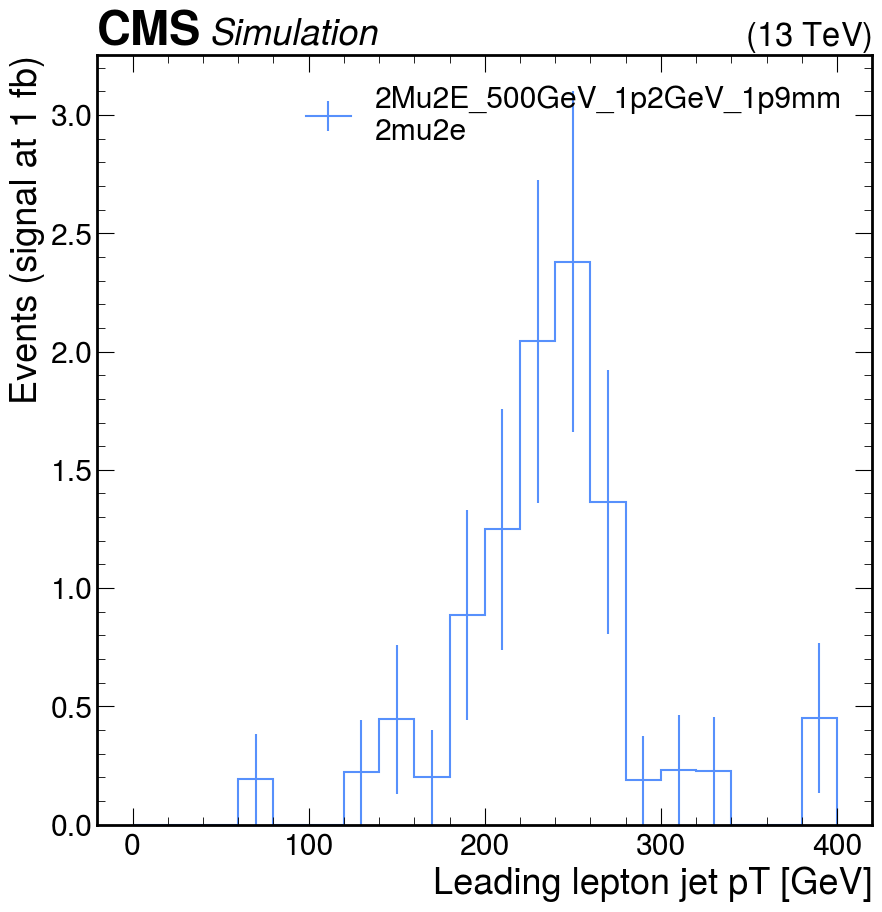

In [11]:
h_all = out["hists"][HIST_NAME]
print(h_all.axes)

h = h_all[{"channel": CHANNEL}]

fig, ax = plt.subplots()
if h.ndim == 1:
    h = h[::hist.rebin(5)]  # fewer, wider bins for 200 events
    utilities.plot(h, ax=ax, label=f"{DATASET}\n{CHANNEL}")
    ax.set_ylabel("Events (signal at 1 fb)")
    ax.legend()
else:
    utilities.plot(h, ax=ax)
plt.show()

### Counters

`out["counters"][lj_reco][channel]` holds a few object counts summed over the events
that pass the channel (for example the number of lepton jets), defined in `counter_defs`
in `sidm/definitions/hists.py`. They are not scaled. Unlike the cutflow, they keep the
`lj_reco` level even when only one reconstruction ran.

In [12]:
lj_reco = proc.lj_reco_choices[0]
for name, value in out["counters"][lj_reco][CHANNEL].items():
    print(f"{name:30s} {value}")

Total LJs                      92
Gen As to muons                46
Gen As to electrons            46
Matched gen As to muons        45
Matched gen As to electrons    46


### Metadata

`out["metadata"]` describes the run. The entries stored as sets keep one value per
setting when chunks are added, so a set with two values means chunks that disagree.

| key | meaning |
|---|---|
| `n_evts` | events read |
| `scaled_sum_weights` | sum of generator weights divided by `skim_factor`, before any cut and before corrections |
| `year`, `is_data`, `production` | copied from the fileset metadata |
| `unweighted_hist` | whether the histograms were filled with unit weights |
| `n_removed_golden_json` | data events removed by the golden JSON (always 0 for simulation) |
| `gen_filter_eff` | the generator-filter efficiency `postprocess` used (simulation only) |
| `corrections` | the corrections applied (present when corrections were requested) |
| `scaled_sum_weights_corrected` | the same sum with each event-level correction applied (simulation with corrections only) |
| `object_corrections` | per channel, which object scale factors were applied, at which working point, from which collection |

In [13]:
for key, value in out["metadata"].items():
    print(f"{key:30s} {value}")

n_evts                         200
scaled_sum_weights             200.0
year                           set_accumulator({'2018'})
is_data                        set_accumulator({False})
production                     set_accumulator({'v10'})
unweighted_hist                set_accumulator({False})
n_removed_golden_json          0
corrections                    set_accumulator({'electron_reco', 'muon_id', 'photon_pixel_veto', 'l1_prefiring', 'pileup'})
scaled_sum_weights_corrected   {'pileup': 199.73851445316672, 'l1_prefiring': 199.28369045257568, 'all_event_level': 199.01980088847978}
object_corrections             {'2mu2e': set_accumulator({'muon_id:looseID:muons', 'electron_reco:always:ljs', 'photon_pixel_veto:pixelSeed:ljs'})}
gen_filter_eff                 set_accumulator({0.7594})


`postprocess` multiplied every weighted number by one factor per sample,
luminosity × cross section × generator-filter efficiency / `scaled_sum_weights`,
computed by `utilities.get_lumixs_weight`. On this path signal is always normalized to
a cross section of 1 fb, which is what the printed message says. `02_normalization.md`
explains each term.

In [14]:
meta = out["metadata"]
production = next(iter(meta["production"]))
factor = utilities.get_lumixs_weight(DATASET, "2018", meta["scaled_sum_weights"], production)
print("scale factor applied by postprocess:", factor)

Ignoring signal cross sections, assuming 1 fb
scale factor applied by postprocess: 0.2271745


## 6. Save and load

`coffea.util.save` writes the whole result to one compressed file and `coffea.util.load`
reads it back, so a long run does not have to be repeated after a kernel restart. Both
work on local files only. This cell writes to a temporary directory that is deleted
afterwards.

For outputs you want to share, the top README describes the common EOS area and the
`.meta.yaml` file written next to each output (`sidm/tools/metadata.py`).

In [15]:
with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, f"{DATASET}.coffea")
    coffea.util.save(result, path)
    print(os.path.basename(path), os.path.getsize(path), "bytes")
    reloaded = coffea.util.load(path)

reloaded["out"][DATASET]["cutflow"][CHANNEL].print_table()

2Mu2E_500GeV_1p2GeV_1p9mm.coffea 10603 bytes
cut name                             raw N    weighted N    weighted %
---------------------------------  -------  ------------  ------------
None                                 200.0          44.1         100.0
pass triggers                         89.0          19.7          44.7
PV filter                             89.0          19.7          44.7
>=2 muons (pf or dsa) pT > 26 GeV     61.0          13.6          30.8
all cosAlpha(mu, mu) > -0.99          61.0          13.6          30.8
>=2 LJs                               46.0          10.1          22.9
2mu2e                                 46.0          10.1          22.9


## Where to go next

- Run more than one channel or collection at once: pass longer lists to
  `SidmProcessor`. Each channel becomes one entry of the `channel` axis and one cutflow.
- Per-event values instead of histograms: build the processor with `debug=True`; see the
  `SidmProcessor` docstring and `sidm/test_notebooks/debug_branch_demo.ipynb`.
- Real samples: `utilities.make_fileset` with `replace_xcache=True` on LPC (top README,
  section 6). The scale table in `tutorials/README.md` says which way to run them.
- How the weighted numbers are normalized: `02_normalization.md`.
- Processing collision data: read `03_data_and_blinding.md` first.